# Экзаменационная задача №5. Расчет стоимости разработки по COCOMO II

- **Курс:** Экономика информатизации, лекция №6 «Классические модели оценки затрат на разработку (COCOMO)»
- **Студент:** Солдатов Сергей Юрьевич
- **Группа:** ПИ4-1
- **Дата:** 2026-11-24

In [1]:
# ============================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №05: РАСЧЕТ СТОИМОСТИ РАЗРАБОТКИ ПО COCOMO II
# ============================================================================
# Дата: 2026-11-24
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ============================================================================

# Библиотеки: pandas — таблицы, matplotlib — графики
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd

MLN = 1_000_000  # рублей в миллионе


def fmt(value, digits=0):
    """Число в привычной записи: 9 200 или 0,6."""
    value = round(value, digits) + 0          # «+ 0» убирает минус у нуля
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",").replace("-", "−")


def short(value, min_digits=0):
    """Число без лишних нулей в конце: 4, 3,72 или 1,10 (min_digits — сколько знаков оставить)."""
    whole, fraction = fmt(value, 4).split(",")
    while len(fraction) > min_digits and fraction.endswith("0"):
        fraction = fraction[:-1]                 # убираем последний ноль
    return whole + ("," + fraction if fraction else "")


def pct(value):
    """Доля в процентах: 0.05 -> 5%, 0.125 -> 12,5%."""
    return short(value * 100) + "%"


# Единый вид графиков: светлый фон, сетка, без верхней и правой рамки
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

# Подписи делений на осях графиков — в той же записи чисел, что и в таблицах
AXIS_FORMAT = FuncFormatter(lambda value, position: fmt(value))

# Цвета на графиках
BLUE, ORANGE, GREEN, PURPLE, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#7c5cc4", "#52514e"

# Графики сохраняем в reports/figures (ноутбук запускается из папки notebooks)
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

## Экономическая постановка задачи

**Проблема.** Государственный заказчик планирует разработку информационной системы «Единый портал поддержки
предпринимателей». До начала работ нужно знать, сколько труда, времени и денег она потребует. Цену нельзя назначить
«на глаз»: в государственных закупках ее нужно обосновать расчетом.

**Актуальность.** По лекции №6 оценка стоимости разработки ПО — сложная задача: проекты уникальны, требования
меняются, производительность команд различается. По статистике из лекции (раздел 1.1) бюджет проектов превышается
на 30–45%. COCOMO II — формальная модель, которая считает трудоемкость по размеру системы и набору коэффициентов.
По лекции (раздел 7.2) ее применяют там, где требуется формальное обоснование цены, в первую очередь в
государственных закупках.

**Цель.** Рассчитать по модели COCOMO II трудоемкость, длительность и стоимость разработки системы и сравнить
результат с методикой г. Москвы.

**Задачи:**
1. посчитать размер системы в тысячах строк кода с учетом повторного использования;
2. посчитать коэффициент масштаба, произведение множителей трудоемкости и саму трудоемкость;
3. посчитать длительность разработки;
4. посчитать прямые затраты, накладные расходы и стоимость без НДС и с НДС;
5. сравнить результат с расчетом по методике г. Москвы (задание лекции №19) и объяснить расхождения.

## 1. Исходные данные

### 1.1. Параметры проекта

Все значения взяты из условия задачи (методичка, лекция №6, раздел «Экзаменационная задача»).

In [2]:
# Все исходные данные лежат в одном словаре: меняем значение — расчеты и графики пересчитаются
BASE = {
    "fp": 450,                       # размер системы в функциональных точках (FP)
    "language": "C#",                # язык программирования
    "k_lang": 54,                    # K_п — строк кода на одну функциональную точку для языка
    "reuse": 0.20,                   # коэффициент повторного использования
    # Коэффициенты масштаба (SF): обозначение, значение, интерпретация из условия
    "scale_factors": [
        ("PREC", 4, "Высокая прецедентность"),
        ("FLEX", 3, "Средняя гибкость"),
        ("RESL", 3, "Средняя устойчивость к рискам"),
        ("TEAM", 4, "Хорошая сплоченность"),
        ("PMAT", 3, "Степень зрелости процессов"),
    ],
    # Множители трудоемкости (EM): обозначение, значение, интерпретация из условия
    "effort_multipliers": [
        ("RELY", 1.15, "Высокая надежность (критичные последствия)"),
        ("DATA", 1.00, "Средняя нагрузка на БД"),
        ("CPLX", 1.15, "Высокая сложность алгоритмов"),
        ("TIME", 1.00, "Нет ограничений по времени"),
        ("STOR", 1.00, "Нет ограничений по памяти"),
        ("ACAP", 1.15, "Высокие способности аналитиков"),
        ("PCAP", 1.10, "Средние способности разработчиков"),
        ("PCON", 1.00, "Текучесть кадров средняя"),
        ("APEX", 1.00, "Средний опыт в предметной области"),
        ("PEXP", 1.00, "Средний опыт в платформе"),
        ("LTEX", 1.00, "Средний опыт в языке"),
        ("TOOL", 1.00, "Стандартные инструменты разработки"),
        ("SITE", 1.00, "Команда в одном офисе"),
        ("SCED", 1.00, "Стандартный срок реализации"),
        ("RUSE", 1.10, "Требуется повторное использование компонентов"),
    ],
    "a": 2.94,                       # A — калибруемая константа модели
    "b_base": 0.91,                  # B_base — базовый показатель степени
    "sf_weight": 0.01,               # множитель перед суммой SF — число 0.01 из формулы задания 2
    "tdev_c": 2.5,                   # множитель в формуле длительности — число 2.5 из задания 5
    "tdev_d": 0.35,                  # показатель степени в формуле длительности (задание 5)
    "pm_cost": 220_000,              # стоимость человеко-месяца, руб.
    "overhead": 0.25,                # накладные расходы (управление, аренда), доля от ФОТ
    "vat": 0.20,                     # НДС
}

# Таблицы коэффициентов строятся из словаря, поэтому всегда совпадают с расчетом
rows = []
for name, value, meaning in BASE["scale_factors"]:
    rows.append({"Коэффициент масштаба": name, "Значение": short(value), "Интерпретация": meaning})
display(pd.DataFrame(rows).set_index("Коэффициент масштаба"))

rows = []
for name, value, meaning in BASE["effort_multipliers"]:
    rows.append({
        "Множитель трудоемкости": name,
        "Значение": short(value, 2),
        "Интерпретация": meaning,
    })
display(pd.DataFrame(rows).set_index("Множитель трудоемкости"))

# Остальные параметры
source_table = pd.DataFrame(
    [
        ("Функциональные точки (FP)", fmt(BASE["fp"])),
        ("Язык программирования", BASE["language"]),
        ("K_п — строк кода на одну функциональную точку", short(BASE["k_lang"])),
        ("Коэффициент повторного использования", pct(BASE["reuse"])),
        ("A", short(BASE["a"], 2)),
        ("B_base", short(BASE["b_base"], 2)),
        ("Множитель перед суммой SF (из формулы задания 2)", short(BASE["sf_weight"], 2)),
        ("Множитель в формуле длительности (из задания 5)", short(BASE["tdev_c"], 1)),
        ("Показатель степени в формуле длительности (из задания 5)", short(BASE["tdev_d"], 2)),
        ("Стоимость человеко-месяца, руб.", fmt(BASE["pm_cost"])),
        ("Накладные расходы (управление, аренда), от ФОТ", pct(BASE["overhead"])),
        ("НДС", pct(BASE["vat"])),
    ],
    columns=["Параметр", "Значение"],
)
display(source_table)

,Значение,Интерпретация
Коэффициент масштаба,,
PREC,4,Высокая прецедентность
FLEX,3,Средняя гибкость
RESL,3,Средняя устойчивость к рискам
TEAM,4,Хорошая сплоченность
PMAT,3,Степень зрелости процессов


,Значение,Интерпретация
Множитель трудоемкости,,
RELY,"1,15",Высокая надежность (критичные последствия)
DATA,"1,00",Средняя нагрузка на БД
CPLX,"1,15",Высокая сложность алгоритмов
TIME,"1,00",Нет ограничений по времени
STOR,"1,00",Нет ограничений по памяти
ACAP,"1,15",Высокие способности аналитиков
PCAP,"1,10",Средние способности разработчиков
PCON,"1,00",Текучесть кадров средняя
APEX,"1,00",Средний опыт в предметной области


,Параметр,Значение
0,Функциональные точки (FP),450
1,Язык программирования,C#
2,K_п — строк кода на одну функциональную точку,54
3,Коэффициент повторного использования,20%
4,A,"2,94"
5,B_base,"0,91"
6,Множитель перед суммой SF (из формулы задания 2),"0,01"
7,Множитель в формуле длительности (из задания 5),"2,5"
8,Показатель степени в формуле длительности (из ...,"0,35"
9,"Стоимость человеко-месяца, руб.",220 000


### 1.2. Справочные данные

Справочные данные вводятся там, где они нужны: формулы из условия и лекции №6 — в разделе 2.1, данные задания
лекции №19 и значения из лекций №17 и №19 для методики г. Москвы — в разделе 2.7.

### 1.3. Дополнительные условия (условия и расчеты)

В условии есть места, которые можно понять по-разному. Каждое такое место разобрано перед тем расчетом, на который
оно влияет: условия У1–У2 — в разделе 2.4, У3–У4 — в разделе 2.6, У5–У10 — в разделе 2.7.

## 2. Расчеты

### 2.1. Математическая модель

Обозначения: $FP$ — число функциональных точек, $K_п$ — строк кода на одну функциональную точку, $k_{повт}$ —
коэффициент повторного использования, $SF_j$ — коэффициенты масштаба, $EM_i$ — множители трудоемкости, $C_{PM}$ —
стоимость человеко-месяца, $h$ — доля накладных расходов, $s$ — ставка НДС.

**Размер системы** (формула задания 1), тысяч строк кода:

$$KLOC = \frac{FP \cdot K_п}{1000} \cdot (1 - k_{повт})$$

**Коэффициент масштаба** (формула задания 2) и **произведение множителей трудоемкости** (формула задания 3):

$$B = B_{base} + 0{,}01 \cdot \sum_{j=1}^{5} SF_j, \qquad EM_{total} = \prod_{i} EM_i$$

**Трудоемкость** (формула задания 4), человеко-месяцев:

$$Effort = A \cdot KLOC^{B} \cdot EM_{total}$$

**Длительность разработки** (формула задания 5), месяцев:

$$TDEV = 2{,}5 \cdot Effort^{0{,}35}$$

**Стоимость** (задания 6–9), рублей:

$$C_{прям} = Effort \cdot C_{PM}, \qquad C_{накл} = h \cdot C_{прям}, \qquad
C_{без\ НДС} = C_{прям} + C_{накл}, \qquad C_{с\ НДС} = C_{без\ НДС} \cdot (1 + s)$$

**Откуда формулы.** Формулы размера, коэффициента масштаба, трудоемкости, длительности и прямых затрат записаны
в заданиях 1–6 условия. В лекции №6 им соответствуют: конвертация функциональных точек в KLOC — раздел 5.3;
основная формула COCOMO II уровня Post-Architecture — раздел 4.3; длительность и стоимость — разделы 6.2 и 6.3.
Коэффициент масштаба в общем виде дан в разделе 4.3, а множитель 0,01 перед суммой — в примерах разделов 4.5 и 6.3
и в задании 2 условия. Множитель $(1 - k_{повт})$ в формуле размера добавлен условием: в лекции повторное
использование названо отличием COCOMO II от COCOMO I (раздел 4.1), но формулы для него нет.

**Почему эти методы.** Расчет идет по пошаговой методике из лекции (раздел 6.2): размер → уровень модели →
коэффициенты масштаба → множители трудоемкости → трудоемкость → длительность → стоимость. Уровень модели выбран
условием: формула задания 4 — это уровень Post-Architecture, полная оценка с учетом всех факторов. По лекции
(раздел 7.2) COCOMO II подходит для государственных закупок и крупных проектов: расчет формальный и прозрачный,
его можно проверить.

### 2.2. Функции расчета

Пять коротких функций — по одной на каждую формулу заданий 1–5. Стоимость (задания 6–9) считается в разделе 2.6
обычными действиями: умножением и сложением.

In [3]:
# Функции повторяют формулы из раздела 2.1
def size_kloc(fp, k_lang, reuse):
    """Размер в тысячах строк кода по формуле задания 1."""
    return fp * k_lang / 1000 * (1 - reuse)


def scale_exponent():
    """Коэффициент масштаба B по формуле задания 2."""
    total = 0
    for name, value, meaning in BASE["scale_factors"]:
        total += value                           # сумма всех коэффициентов масштаба
    return BASE["b_base"] + BASE["sf_weight"] * total


def multipliers_product():
    """Произведение всех множителей трудоемкости EM_total (задание 3)."""
    product = 1
    for name, value, meaning in BASE["effort_multipliers"]:
        product *= value                         # перемножаем множители по одному
    return product


def effort_pm(kloc, b, em_total):
    """Трудоемкость в человеко-месяцах по формуле задания 4."""
    return BASE["a"] * kloc ** b * em_total


def duration_months(effort):
    """Длительность разработки в месяцах по формуле задания 5."""
    return BASE["tdev_c"] * effort ** BASE["tdev_d"]

### 2.3. Часть 1. Размер системы (задание 1)

Размер системы задан в функциональных точках. Формула COCOMO II работает с тысячами строк кода, поэтому
функциональные точки переводим в строки через коэффициент языка $K_п$. Часть кода берется из предыдущих проектов —
ее писать не нужно, и она из размера исключается.

In [4]:
# Задание 1. Размер системы в тысячах строк кода (KLOC) с учетом повторного использования
kloc_all = size_kloc(BASE["fp"], BASE["k_lang"], 0)              # весь код системы
KLOC = size_kloc(BASE["fp"], BASE["k_lang"], BASE["reuse"])      # код, который нужно написать

print(f"Весь код системы: {fmt(BASE['fp'])} × {short(BASE['k_lang'])} / 1000 = "
      f"{short(kloc_all, 2)} тыс. строк")
print(f"Берется из предыдущих проектов ({pct(BASE['reuse'])}): "
      f"{short(kloc_all - KLOC, 2)} тыс. строк")
print(f"Ответ на задание 1: KLOC = {fmt(BASE['fp'])} × {short(BASE['k_lang'])} / 1000 × "
      f"(1 − {short(BASE['reuse'], 2)}) = {short(KLOC, 2)} тыс. строк кода")

Весь код системы: 450 × 54 / 1000 = 24,30 тыс. строк
Берется из предыдущих проектов (20%): 4,86 тыс. строк
Ответ на задание 1: KLOC = 450 × 54 / 1000 × (1 − 0,20) = 19,44 тыс. строк кода


### 2.4. Часть 2. Трудозатраты (задания 2–4)

Для этих расчетов нужны два условия.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У1 | В произведение входят все множители из таблицы условия — их 15. Факторы DOCU и PVOL из таблицы лекции (раздел 4.4) в условии не заданы и в расчет не входят. Множитель LTEX взят из условия, хотя в таблице лекции его нет | В критериях оценки: «корректное произведение всех 15 множителей». Не учитывать множитель — то же, что принять его равным 1,00 (среднее значение по лекции) |
| У2 | Промежуточные результаты не округляются: в каждую следующую формулу подставляется точное значение. В строках расчета сомножители показаны округленно, поэтому при проверке на калькуляторе последние знаки могут отличаться | Так результат не зависит от того, до какого знака округлять на каждом шаге. В примере лекции (раздел 6.3) промежуточные числа округлены |

In [5]:
# Задание 2. Коэффициент масштаба B
rows = []
sf_sum = 0
for name, value, meaning in BASE["scale_factors"]:
    sf_sum += value
    rows.append({"Коэффициент масштаба": name, "Значение": short(value), "Интерпретация": meaning})
rows.append({"Коэффициент масштаба": "Сумма SF", "Значение": short(sf_sum), "Интерпретация": ""})
display(pd.DataFrame(rows).set_index("Коэффициент масштаба"))

B = scale_exponent()
print(f"Ответ на задание 2: B = {short(BASE['b_base'], 2)} + {short(BASE['sf_weight'], 2)} × "
      f"{short(sf_sum)} = {short(B, 2)}")
if B > 1:
    print("  B больше 1: трудоемкость растет быстрее, чем размер системы.")
elif B < 1:
    print("  B меньше 1: трудоемкость растет медленнее, чем размер системы.")
else:
    print("  B равен 1: трудоемкость растет пропорционально размеру системы.")

,Значение,Интерпретация
Коэффициент масштаба,,
PREC,4,Высокая прецедентность
FLEX,3,Средняя гибкость
RESL,3,Средняя устойчивость к рискам
TEAM,4,Хорошая сплоченность
PMAT,3,Степень зрелости процессов
Сумма SF,17,


Ответ на задание 2: B = 0,91 + 0,01 × 17 = 1,08
  B больше 1: трудоемкость растет быстрее, чем размер системы.


In [6]:
# Задание 3. Произведение всех множителей трудоемкости
changing = []                                    # множители, которые не равны 1
neutral = 0                                      # сколько множителей равны 1
for name, value, meaning in BASE["effort_multipliers"]:
    if value == 1:
        neutral += 1
    else:
        changing.append((name, value, meaning))

# Множители, которые меняют трудоемкость
rows = []
values_text = []
for name, value, meaning in changing:
    rows.append({
        "Множитель": name,
        "Значение": short(value, 2),
        "Интерпретация": meaning,
        "Изменение трудоемкости": ("+" if value > 1 else "") + pct(value - 1),
    })
    values_text.append(short(value, 2))
if rows:
    display(pd.DataFrame(rows).set_index("Множитель"))

EM_TOTAL = multipliers_product()
print(f"Всего множителей: {len(BASE['effort_multipliers'])}. Из них {neutral} равны 1,00 "
      "и на произведение не влияют.")
if values_text:
    print(f"Ответ на задание 3: EM_total = {' × '.join(values_text)} = {fmt(EM_TOTAL, 4)}")
else:
    print(f"Ответ на задание 3: EM_total = {fmt(EM_TOTAL, 4)} — все множители равны 1,00")

,Значение,Интерпретация,Изменение трудоемкости
Множитель,,,
RELY,"1,15",Высокая надежность (критичные последствия),+15%
CPLX,"1,15",Высокая сложность алгоритмов,+15%
ACAP,"1,15",Высокие способности аналитиков,+15%
PCAP,"1,10",Средние способности разработчиков,+10%
RUSE,"1,10",Требуется повторное использование компонентов,+10%


Всего множителей: 15. Из них 10 равны 1,00 и на произведение не влияют.
Ответ на задание 3: EM_total = 1,15 × 1,15 × 1,15 × 1,10 × 1,10 = 1,8403


In [7]:
# Задание 4. Трудоемкость разработки
size_power = KLOC ** B                           # размер в степени B
effort_nominal = BASE["a"] * size_power          # трудоемкость, если бы все множители были равны 1
EFFORT = effort_pm(KLOC, B, EM_TOTAL)            # трудоемкость с учетом множителей

print(f"KLOC^B = {short(KLOC, 2)}^{short(B, 2)} = {fmt(size_power, 4)}")
print(f"A × KLOC^B = {short(BASE['a'], 2)} × {fmt(size_power, 4)} = "
      f"{fmt(effort_nominal, 2)} чел.-мес. — трудоемкость без множителей")
print(f"Ответ на задание 4: Effort = {short(BASE['a'], 2)} × {fmt(size_power, 4)} × "
      f"{fmt(EM_TOTAL, 4)} = {fmt(EFFORT, 2)} чел.-мес.")

KLOC^B = 19,44^1,08 = 24,6486
A × KLOC^B = 2,94 × 24,6486 = 72,47 чел.-мес. — трудоемкость без множителей
Ответ на задание 4: Effort = 2,94 × 24,6486 × 1,8403 = 133,36 чел.-мес.


### 2.5. Часть 3. Длительность разработки (задание 5)

Длительность считается от трудоемкости. Показатель степени меньше единицы, поэтому срок растет намного медленнее
трудоемкости: большой проект делает большая команда.

In [8]:
# Задание 5. Длительность разработки
effort_power = EFFORT ** BASE["tdev_d"]          # трудоемкость в степени из формулы
TDEV = duration_months(EFFORT)

print(f"Effort^{short(BASE['tdev_d'], 2)} = {fmt(EFFORT, 4)}^{short(BASE['tdev_d'], 2)} = "
      f"{fmt(effort_power, 4)}")
print(f"Ответ на задание 5: TDEV = {short(BASE['tdev_c'], 1)} × {fmt(effort_power, 4)} = "
      f"{fmt(TDEV, 2)} мес.")

Effort^0,35 = 133,3577^0,35 = 5,5431
Ответ на задание 5: TDEV = 2,5 × 5,5431 = 13,86 мес.


### 2.6. Часть 4. Стоимость разработки (задания 6–9)

Для расчета стоимости нужны два условия.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У3 | ФОТ (фонд оплаты труда) — это прямые затраты на разработку из задания 6. Накладные расходы = 25% от прямых затрат | Стоимость человеко-месяца — это оплата труда исполнителей, а других затрат на труд в условии нет |
| У4 | Полная стоимость без НДС = прямые затраты + накладные расходы. НДС начисляется на полную стоимость. Прибыль исполнителя и другие затраты не добавляются | В условии заданы только стоимость человеко-месяца, накладные расходы и НДС |

In [9]:
# Задание 6. Прямые затраты на разработку
DIRECT = EFFORT * BASE["pm_cost"]
print(f"Ответ на задание 6: Стоимость_прямая = {fmt(EFFORT, 4)} × {fmt(BASE['pm_cost'])} = "
      f"{fmt(DIRECT / MLN, 2)} млн руб. ({fmt(DIRECT)} руб.)")

Ответ на задание 6: Стоимость_прямая = 133,3577 × 220 000 = 29,34 млн руб. (29 338 700 руб.)


In [10]:
# Задание 7. Накладные расходы: доля от ФОТ, то есть от прямых затрат (условие У3)
OVERHEAD = DIRECT * BASE["overhead"]
print(f"Ответ на задание 7: накладные расходы = {fmt(DIRECT)} × {pct(BASE['overhead'])} = "
      f"{fmt(OVERHEAD / MLN, 2)} млн руб. ({fmt(OVERHEAD)} руб.)")

Ответ на задание 7: накладные расходы = 29 338 700 × 25% = 7,33 млн руб. (7 334 675 руб.)


In [11]:
# Задание 8. Полная стоимость без НДС: прямые затраты плюс накладные расходы
COST_NET = DIRECT + OVERHEAD
print(f"Ответ на задание 8: полная стоимость без НДС = {fmt(DIRECT)} + {fmt(OVERHEAD)} = "
      f"{fmt(COST_NET / MLN, 2)} млн руб. ({fmt(COST_NET)} руб.)")

Ответ на задание 8: полная стоимость без НДС = 29 338 700 + 7 334 675 = 36,67 млн руб. (36 673 375 руб.)


In [12]:
# Задание 9. Стоимость с НДС
VAT = COST_NET * BASE["vat"]                     # сумма НДС
COST_GROSS = COST_NET + VAT
print(f"НДС = {fmt(COST_NET)} × {pct(BASE['vat'])} = {fmt(VAT / MLN, 2)} млн руб. "
      f"({fmt(VAT)} руб.)")
print(f"Ответ на задание 9: стоимость с НДС = {fmt(COST_NET)} + {fmt(VAT)} = "
      f"{fmt(COST_GROSS / MLN, 2)} млн руб. ({fmt(COST_GROSS)} руб.)")

# Сводная таблица стоимости
cost_table = pd.DataFrame(
    [
        ("Прямые затраты (задание 6)", fmt(DIRECT), fmt(DIRECT / MLN, 2)),
        ("Накладные расходы (задание 7)", fmt(OVERHEAD), fmt(OVERHEAD / MLN, 2)),
        ("Полная стоимость без НДС (задание 8)", fmt(COST_NET), fmt(COST_NET / MLN, 2)),
        ("НДС", fmt(VAT), fmt(VAT / MLN, 2)),
        ("Стоимость с НДС (задание 9)", fmt(COST_GROSS), fmt(COST_GROSS / MLN, 2)),
    ],
    columns=["Показатель", "руб.", "млн руб."],
)
display(cost_table.set_index("Показатель"))

НДС = 36 673 375 × 20% = 7,33 млн руб. (7 334 675 руб.)
Ответ на задание 9: стоимость с НДС = 36 673 375 + 7 334 675 = 44,01 млн руб. (44 008 050 руб.)


,руб.,млн руб.
Показатель,,
Прямые затраты (задание 6),29 338 700,"29,34"
Накладные расходы (задание 7),7 334 675,"7,33"
Полная стоимость без НДС (задание 8),36 673 375,"36,67"
НДС,7 334 675,"7,33"
Стоимость с НДС (задание 9),44 008 050,"44,01"


### 2.7. Часть 5. Сравнение с методикой г. Москвы (задание 10)

Задание 10 просит сравнить результат с методикой г. Москвы и ссылается на задание лекции №19. Поэтому считаем это
задание по формулам лекции №19 и ставим его результаты рядом с нашими.

**Справочные данные** (лекции №19 и №17):

- задание лекции №19: 450 функциональных точек, язык Java, коэффициенты трудоемкости МТi = 0,85,
  продолжительность 6 месяцев, рентабельность 10%;
- размер ИС: $РР = ФТ \cdot К_п / 1000$ (лекция №19, раздел 2.1), для Java $К_п = 53$ (раздел 2.3);
- трудозатраты: $ОТр = A \cdot РР^{B} \cdot \prod МТ_i$, где $A = 5{,}17$ и $B = 0{,}94$ (раздел 4.1);
- численность по группам: $Ч_i = (ОТр / Т_п) \cdot К_{чi}$ (раздел 5.1);
- средняя выработка: $В_{ср} = ЗПБ_{2015} \cdot К_{пер} \cdot (1 + Р) / К_3$, где $ЗПБ_{2015} = 78\,300$ руб.
  и $К_3 = 0{,}65$ (раздел 5.3);
- стоимость работ: $Ц = В_{ср} \cdot Т_п \cdot Ч_п \cdot К_{кв(уч)}$ (раздел 5.3);
- коэффициент пересчета $К_{пер} = 1{,}064$ и коэффициент квалификации $К_{кв(уч)} = 0{,}874$ — из примера расчета
  НМЦК в лекции №17 (раздел 4.4); то же значение $К_{кв(уч)}$ стоит в примере лекции №19 (раздел 6).

В задании лекции №19 заданы не все величины из этих формул, поэтому для сравнения нужны шесть условий.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У5 | Сравниваем с заданием лекции №19 при его исходных данных. К нашей системе методику г. Москвы не применяем | Задание 10 прямо ссылается на задание лекции №19. Для нашей системы коэффициенты МТ1–МТ7 в условии не заданы |
| У6 | «МТi = 0,85» — это произведение всех коэффициентов трудоемкости МТ1–МТ7, а не значение каждого из них | В примере лекции №19 (раздел 4.2) записано так же: «МТ1-МТ7 = 0.740 (произведение)» |
| У7 | Коэффициент пересчета $К_{пер} = 1{,}064$ | В задании лекции №19 он не задан. Это значение из примера расчета НМЦК в лекции №17 (раздел 4.4) — другого в методичке нет |
| У8 | Коэффициент квалификации $К_{кв(уч)} = 0{,}874$ | Для расчета по формуле лекции №19 (раздел 5.2) нужны коэффициенты участия, а их в лекции нет. Значение 0,874 стоит в примерах лекций №17 и №19 |
| У9 | Численность по группам не округляется. Руководитель проекта — один человек сверх расчета по формуле | Правил округления в лекции №19 нет. У руководителя проекта в таблице вместо коэффициента численности записано: «назначается отдельно» |
| У10 | Стоимость сравниваем без НДС | По лекции №19 (раздел 1.3) НДС в стоимость работ не включается, а ставка НДС в задании лекции №19 не задана |

In [13]:
# Данные задания лекции №19 и справочные значения методики г. Москвы из лекций №19 и №17
MOSCOW = {
    "fp": 450,                       # функциональные точки (задание лекции №19)
    "language": "Java",              # язык (задание лекции №19)
    "k_lang": 53,                    # Кп для Java (лекция №19, раздел 2.3)
    "mt_product": 0.85,              # произведение коэффициентов МТ1–МТ7 (условие У6)
    "months": 6,                     # плановая продолжительность Тп, мес. (задание лекции №19)
    "profit": 0.10,                  # рентабельность Р (задание лекции №19)
    "a": 5.17,                       # коэффициент A (лекция №19, раздел 4.1)
    "b": 0.94,                       # коэффициент B (лекция №19, раздел 4.1)
    "base_salary": 78_300,           # ЗПБ2015 — базовая зарплата, руб. (лекция №19, раздел 5.3)
    "salary_share": 0.65,            # К3 — доля зарплаты (лекция №19, раздел 5.3)
    "recalc": 1.064,                 # Кпер — коэффициент пересчета (лекция №17; условие У7)
    "qualification": 0.874,          # Ккв(уч) — коэффициент квалификации (условие У8)
    "managers": 1,                   # руководитель проекта назначается отдельно (условие У9)
    "staff_ratio_range": (10, 30),   # для каких ОТр / Тп дана таблица коэффициентов численности
    # Группы исполнителей: должность и коэффициент численности Кч (лекция №19, раздел 5.1)
    "staff": [
        ("Зам. руководителя", 0.058),
        ("Главный архитектор", 0.058),
        ("Архитектор, методолог", 0.231),
        ("Старший аналитик", 0.058),
        ("Аналитик, разработчик", 0.520),
        ("Тестировщик", 0.173),
    ],
}

moscow_source = pd.DataFrame(
    [
        ("Функциональные точки (ФТ)", fmt(MOSCOW["fp"])),
        ("Язык программирования", MOSCOW["language"]),
        ("Кп — коэффициент преобразования для языка", short(MOSCOW["k_lang"])),
        ("Произведение коэффициентов трудоемкости МТ1–МТ7", short(MOSCOW["mt_product"], 2)),
        ("Плановая продолжительность Тп, мес.", short(MOSCOW["months"])),
        ("Рентабельность Р", pct(MOSCOW["profit"])),
        ("A", short(MOSCOW["a"], 2)),
        ("B", short(MOSCOW["b"], 2)),
        ("Базовая зарплата ЗПБ2015, руб.", fmt(MOSCOW["base_salary"])),
        ("Доля зарплаты К3", short(MOSCOW["salary_share"], 2)),
        ("Коэффициент пересчета Кпер (условие У7)", short(MOSCOW["recalc"], 2)),
        ("Коэффициент квалификации Ккв(уч) (условие У8)", short(MOSCOW["qualification"], 2)),
        ("Руководителей проекта (условие У9)", short(MOSCOW["managers"])),
    ],
    columns=["Параметр", "Значение"],
)
display(moscow_source)

,Параметр,Значение
0,Функциональные точки (ФТ),450
1,Язык программирования,Java
2,Кп — коэффициент преобразования для языка,53
3,Произведение коэффициентов трудоемкости МТ1–МТ7,"0,85"
4,"Плановая продолжительность Тп, мес.",6
5,Рентабельность Р,10%
6,A,"5,17"
7,B,"0,94"
8,"Базовая зарплата ЗПБ2015, руб.",78 300
9,Доля зарплаты К3,"0,65"


In [14]:
# Методика г. Москвы, этапы 1 и 2: размер ИС и трудозатраты
M_SIZE = MOSCOW["fp"] * MOSCOW["k_lang"] / 1000                  # размер ИС (РР), тыс. строк
m_size_power = M_SIZE ** MOSCOW["b"]                             # размер в степени B
m_effort_nominal = MOSCOW["a"] * m_size_power                    # трудозатраты без МТ
M_EFFORT = m_effort_nominal * MOSCOW["mt_product"]               # общие трудозатраты (ОТр)

print(f"РР = {fmt(MOSCOW['fp'])} × {short(MOSCOW['k_lang'])} / 1000 = "
      f"{short(M_SIZE, 2)} тыс. строк")
print(f"РР^B = {short(M_SIZE, 2)}^{short(MOSCOW['b'], 2)} = {fmt(m_size_power, 4)}")
print(f"A × РР^B = {short(MOSCOW['a'], 2)} × {fmt(m_size_power, 4)} = "
      f"{fmt(m_effort_nominal, 2)} чел.-мес. — трудозатраты без коэффициентов МТ")
print(f"ОТр = {short(MOSCOW['a'], 2)} × {fmt(m_size_power, 4)} × "
      f"{short(MOSCOW['mt_product'], 2)} = {fmt(M_EFFORT, 2)} чел.-мес.")

РР = 450 × 53 / 1000 = 23,85 тыс. строк
РР^B = 23,85^0,94 = 19,7169
A × РР^B = 5,17 × 19,7169 = 101,94 чел.-мес. — трудозатраты без коэффициентов МТ
ОТр = 5,17 × 19,7169 × 0,85 = 86,65 чел.-мес.


In [15]:
# Методика г. Москвы, этап 3: численность исполнителей и стоимость работ
staff_ratio = M_EFFORT / MOSCOW["months"]        # ОТр / Тп
low, high = MOSCOW["staff_ratio_range"]
print(f"ОТр / Тп = {fmt(M_EFFORT, 2)} / {short(MOSCOW['months'])} = {fmt(staff_ratio, 4)}")
if low <= staff_ratio <= high:
    print(f"  Значение в диапазоне {low}–{high}: таблица коэффициентов численности "
          "из лекции подходит.")
else:
    print(f"  Значение вне диапазона {low}–{high}: таблица коэффициентов численности из лекции "
          "дана для другого диапазона, результат приблизительный.")

# Численность по группам: руководитель назначается отдельно, остальные — по формуле
rows = [{
    "Должность": "Руководитель проекта",
    "Кч": "назначается отдельно",
    "Численность, чел.": fmt(MOSCOW["managers"], 2),
}]
k_sum = 0                                        # сумма коэффициентов численности
M_STAFF = MOSCOW["managers"]                     # общая численность (Чп)
for position, staff_k in MOSCOW["staff"]:
    people = staff_ratio * staff_k               # численность группы (Чi)
    k_sum += staff_k
    M_STAFF += people
    rows.append({
        "Должность": position,
        "Кч": fmt(staff_k, 3),
        "Численность, чел.": fmt(people, 2),
    })
rows.append({"Должность": "Всего (Чп)", "Кч": fmt(k_sum, 3), "Численность, чел.": fmt(M_STAFF, 2)})
display(pd.DataFrame(rows).set_index("Должность"))

M_PAID = M_STAFF * MOSCOW["months"]              # оплачиваемые человеко-месяцы: Чп × Тп
# Средняя выработка: базовая зарплата с пересчетом и рентабельностью, деленная на долю зарплаты
M_OUTPUT = (MOSCOW["base_salary"] * MOSCOW["recalc"] * (1 + MOSCOW["profit"])
            / MOSCOW["salary_share"])
M_PM_PRICE = M_OUTPUT * MOSCOW["qualification"]  # стоимость одного оплачиваемого чел.-мес.
M_COST = M_OUTPUT * MOSCOW["months"] * M_STAFF * MOSCOW["qualification"]     # стоимость без НДС

print(f"Общая численность Чп = {fmt(staff_ratio, 4)} × {fmt(k_sum, 3)} + "
      f"{short(MOSCOW['managers'])} = {fmt(M_STAFF, 4)} чел.")
print(f"Средняя выработка Вср = {fmt(MOSCOW['base_salary'])} × {short(MOSCOW['recalc'], 2)} × "
      f"(1 + {short(MOSCOW['profit'], 2)}) / {short(MOSCOW['salary_share'], 2)} = "
      f"{fmt(M_OUTPUT)} руб. на человека в месяц")
print(f"Стоимость работ Ц = {fmt(M_OUTPUT)} × {short(MOSCOW['months'])} × {fmt(M_STAFF, 4)} × "
      f"{short(MOSCOW['qualification'], 2)} = {fmt(M_COST / MLN, 2)} млн руб. без НДС "
      f"({fmt(M_COST)} руб.)")

ОТр / Тп = 86,65 / 6 = 14,4410
  Значение в диапазоне 10–30: таблица коэффициентов численности из лекции подходит.


,Кч,"Численность, чел."
Должность,,
Руководитель проекта,назначается отдельно,"1,00"
Зам. руководителя,"0,058","0,84"
Главный архитектор,"0,058","0,84"
"Архитектор, методолог","0,231","3,34"
Старший аналитик,"0,058","0,84"
"Аналитик, разработчик","0,520","7,51"
Тестировщик,"0,173","2,50"
Всего (Чп),"1,098","16,86"


Общая численность Чп = 14,4410 × 1,098 + 1 = 16,8562 чел.
Средняя выработка Вср = 78 300 × 1,064 × (1 + 0,10) / 0,65 = 140 988 руб. на человека в месяц
Стоимость работ Ц = 140 988 × 6 × 16,8562 × 0,874 = 12,46 млн руб. без НДС (12 462 511 руб.)


In [16]:
# Задание 10. Результаты двух расчетов рядом
# Дополнительные показатели для сравнения (в заданиях 1–9 их нет):
TEAM = EFFORT / TDEV                             # средняя численность: трудоемкость / длительность
PM_PRICE = COST_NET / EFFORT                     # стоимость одного чел.-мес. без НДС, COCOMO II

comparison = pd.DataFrame(
    [
        ("Функциональные точки", fmt(BASE["fp"]), fmt(MOSCOW["fp"])),
        ("Язык и строк кода на функциональную точку",
         f"{BASE['language']}, {short(BASE['k_lang'])}",
         f"{MOSCOW['language']}, {short(MOSCOW['k_lang'])}"),
        ("Повторное использование кода", pct(BASE["reuse"]), "в формуле не учитывается"),
        ("Размер, тыс. строк кода", short(KLOC, 2), short(M_SIZE, 2)),
        ("Константа A", short(BASE["a"], 2), short(MOSCOW["a"], 2)),
        ("Показатель степени B", short(B, 2), short(MOSCOW["b"], 2)),
        ("Трудозатраты без множителей, чел.-мес.",
         fmt(effort_nominal, 2), fmt(m_effort_nominal, 2)),
        ("Произведение множителей", fmt(EM_TOTAL, 2), short(MOSCOW["mt_product"], 2)),
        ("Трудозатраты, чел.-мес.", fmt(EFFORT, 2), fmt(M_EFFORT, 2)),
        ("Длительность, мес.", f"{fmt(TDEV, 2)} (расчет)", f"{short(MOSCOW['months'])} (задана)"),
        ("Средняя численность (трудозатраты / длительность), чел.",
         fmt(TEAM, 1), fmt(staff_ratio, 1)),
        ("Оплачиваемые чел.-мес.", fmt(EFFORT, 2), f"{fmt(M_PAID, 2)} (Чп × Тп)"),
        ("Стоимость одного оплачиваемого чел.-мес. без НДС, руб.",
         fmt(PM_PRICE), fmt(M_PM_PRICE)),
        ("Стоимость без НДС, млн руб.", fmt(COST_NET / MLN, 2), fmt(M_COST / MLN, 2)),
    ],
    columns=["Показатель", "COCOMO II (наша задача)", "Методика г. Москвы (задание лекции №19)"],
)
display(comparison.set_index("Показатель"))

# Из чего складываются расхождения
effort_ratio = EFFORT / M_EFFORT                 # во сколько раз различаются трудозатраты
multipliers_ratio = EM_TOTAL / MOSCOW["mt_product"]
nominal_ratio = effort_nominal / m_effort_nominal
cost_ratio = COST_NET / M_COST                   # во сколько раз различается стоимость
paid_ratio = EFFORT / M_PAID
price_ratio = PM_PRICE / M_PM_PRICE

print(f"Ответ на задание 10: трудозатраты по COCOMO II — {fmt(EFFORT, 2)} чел.-мес., по методике "
      f"г. Москвы — {fmt(M_EFFORT, 2)} чел.-мес. (отношение {fmt(effort_ratio, 2)}).")
print("  Отношение трудозатрат = отношение множителей × отношение трудозатрат без множителей: "
      f"{fmt(effort_ratio, 2)} = {fmt(multipliers_ratio, 2)} × {fmt(nominal_ratio, 2)}.")
print(f"  Стоимость без НДС — {fmt(COST_NET / MLN, 2)} и {fmt(M_COST / MLN, 2)} млн руб. "
      f"(отношение {fmt(cost_ratio, 2)}).")
print("  Отношение стоимости = отношение оплачиваемых чел.-мес. × отношение цены чел.-мес.: "
      f"{fmt(cost_ratio, 2)} = {fmt(paid_ratio, 2)} × {fmt(price_ratio, 2)}.")
print("  Причины расхождений разобраны в разделе 3.2.")

,COCOMO II (наша задача),Методика г. Москвы (задание лекции №19)
Показатель,,
Функциональные точки,450,450
Язык и строк кода на функциональную точку,"C#, 54","Java, 53"
Повторное использование кода,20%,в формуле не учитывается
"Размер, тыс. строк кода","19,44","23,85"
Константа A,"2,94","5,17"
Показатель степени B,"1,08","0,94"
"Трудозатраты без множителей, чел.-мес.","72,47","101,94"
Произведение множителей,"1,84","0,85"
"Трудозатраты, чел.-мес.","133,36","86,65"


Ответ на задание 10: трудозатраты по COCOMO II — 133,36 чел.-мес., по методике г. Москвы — 86,65 чел.-мес. (отношение 1,54).
  Отношение трудозатрат = отношение множителей × отношение трудозатрат без множителей: 1,54 = 2,17 × 0,71.
  Стоимость без НДС — 36,67 и 12,46 млн руб. (отношение 2,94).
  Отношение стоимости = отношение оплачиваемых чел.-мес. × отношение цены чел.-мес.: 2,94 = 1,32 × 2,23.
  Причины расхождений разобраны в разделе 3.2.


### 2.8. Визуализация результатов

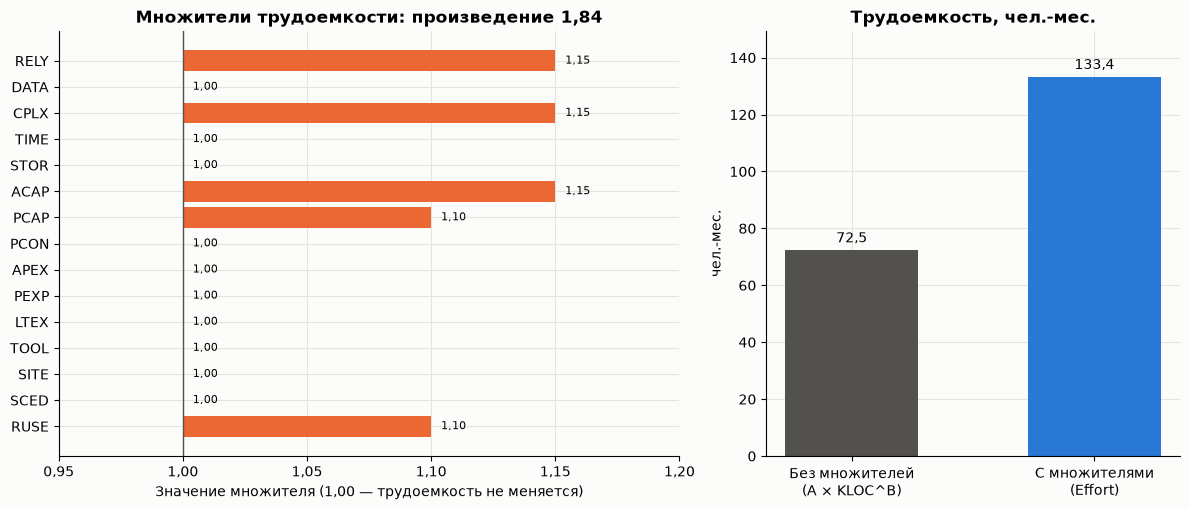

In [17]:
# График 1. Множители трудоемкости и их влияние на трудоемкость
names = []
values = []
colors = []
for name, value, meaning in BASE["effort_multipliers"]:
    names.append(name)
    values.append(value)
    # Оранжевый — множитель увеличивает трудоемкость, зеленый — уменьшает
    colors.append(ORANGE if value >= 1 else GREEN)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [3, 2]})

# Слева — отклонение каждого множителя от 1: столбец идет от линии «1,00» до значения множителя
positions = np.arange(len(names))
deviations = []
for value in values:
    deviations.append(value - 1)
left.barh(positions, deviations, left=1, color=colors)
left.axvline(1, color=GRAY, linewidth=1)
for position, value in zip(positions, values):
    # Подпись справа от столбца, а если множитель меньше 1 — слева
    if value >= 1:
        left.text(value + 0.004, position, short(value, 2), va="center", ha="left", fontsize=8)
    else:
        left.text(value - 0.004, position, short(value, 2), va="center", ha="right", fontsize=8)
left.set_yticks(positions, names)
left.invert_yaxis()
left.set_xlim(min(min(values), 1) - 0.05, max(max(values), 1) + 0.05)
left.xaxis.set_major_formatter(FuncFormatter(lambda value, position: fmt(value, 2)))
left.set_xlabel("Значение множителя (1,00 — трудоемкость не меняется)")
left.set_title(f"Множители трудоемкости: произведение {fmt(EM_TOTAL, 2)}")

# Справа — трудоемкость без множителей и с ними
bars = right.bar(["Без множителей\n(A × KLOC^B)", "С множителями\n(Effort)"],
                 [effort_nominal, EFFORT], color=[GRAY, BLUE], width=0.55)
right.bar_label(bars, labels=[fmt(effort_nominal, 1), fmt(EFFORT, 1)], padding=3)
right.set_ylabel("чел.-мес.")
right.set_title("Трудоемкость, чел.-мес.")
right.yaxis.set_major_formatter(AXIS_FORMAT)
right.margins(y=0.12)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "05_effort.png"), dpi=160, bbox_inches="tight")
plt.show()

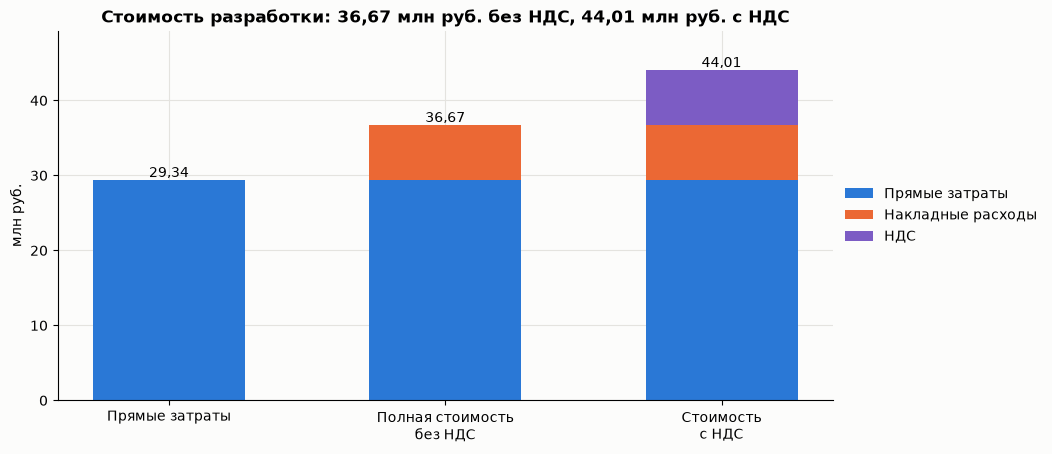

In [18]:
# График 2. Из чего складывается стоимость разработки
labels = ["Прямые затраты", "Полная стоимость\nбез НДС", "Стоимость\nс НДС"]
direct_part = np.array([DIRECT, DIRECT, DIRECT]) / MLN           # прямые — во всех столбцах
overhead_part = np.array([0, OVERHEAD, OVERHEAD]) / MLN          # накладные — во втором и третьем
vat_part = np.array([0, 0, VAT]) / MLN                           # НДС — только в третьем
totals = [DIRECT / MLN, COST_NET / MLN, COST_GROSS / MLN]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(labels, direct_part, color=BLUE, width=0.55, label="Прямые затраты")
ax.bar(labels, overhead_part, bottom=direct_part, color=ORANGE, width=0.55,
       label="Накладные расходы")
ax.bar(labels, vat_part, bottom=direct_part + overhead_part, color=PURPLE, width=0.55, label="НДС")
# Итог над каждым столбцом
for index, total in enumerate(totals):
    ax.text(index, total, fmt(total, 2), ha="center", va="bottom", fontsize=10)
ax.set_ylabel("млн руб.")
ax.set_title(f"Стоимость разработки: {fmt(COST_NET / MLN, 2)} млн руб. без НДС, "
             f"{fmt(COST_GROSS / MLN, 2)} млн руб. с НДС")
ax.yaxis.set_major_formatter(AXIS_FORMAT)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))    # легенда справа
ax.margins(y=0.12)
fig.savefig(os.path.join(FIG_DIR, "05_cost.png"), dpi=160, bbox_inches="tight")
plt.show()

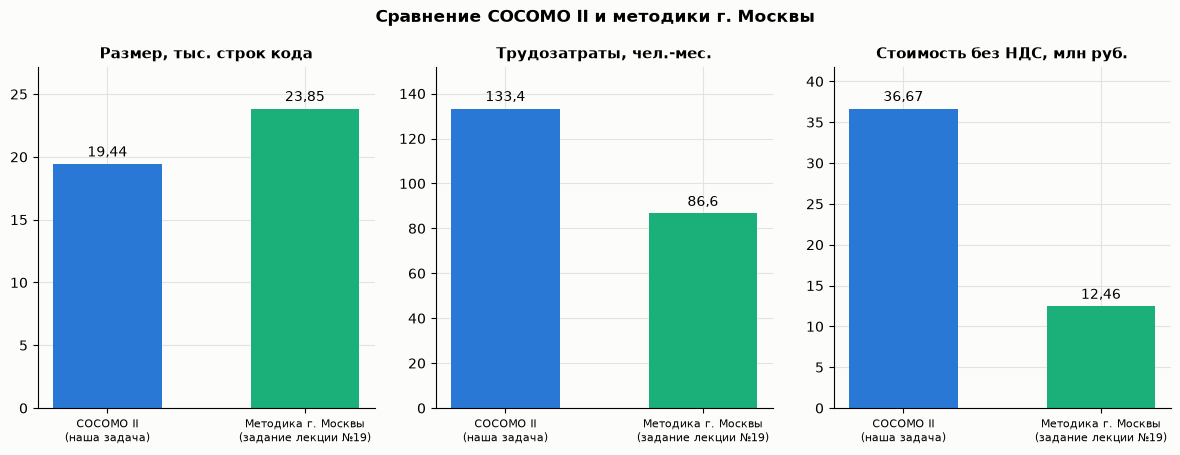

In [19]:
# График 3 (задание 10). COCOMO II и методика г. Москвы: размер, трудозатраты, стоимость
panels = (
    ("Размер, тыс. строк кода", KLOC, M_SIZE, 2),
    ("Трудозатраты, чел.-мес.", EFFORT, M_EFFORT, 1),
    ("Стоимость без НДС, млн руб.", COST_NET / MLN, M_COST / MLN, 2),
)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, (title, ours, moscow, digits) in zip(axes, panels):
    bars = ax.bar(["COCOMO II\n(наша задача)", "Методика г. Москвы\n(задание лекции №19)"],
                  [ours, moscow], color=[BLUE, GREEN], width=0.55)
    ax.bar_label(bars, labels=[fmt(ours, digits), fmt(moscow, digits)], padding=3)
    ax.set_title(title, fontsize=11)
    ax.yaxis.set_major_formatter(AXIS_FORMAT)
    ax.tick_params(axis="x", labelsize=8)
    ax.margins(y=0.14)
fig.suptitle("Сравнение COCOMO II и методики г. Москвы", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "05_comparison.png"), dpi=160, bbox_inches="tight")
plt.show()

In [20]:
# Сохраняем главные показатели в файл reports/05_summary.json
summary = {
    "kloc": KLOC,
    "scale_factors_sum": sf_sum,
    "b": B,
    "em_total": EM_TOTAL,
    "effort_without_multipliers_pm": effort_nominal,
    "effort_pm": EFFORT,
    "tdev_months": TDEV,
    "direct_cost": DIRECT,
    "overhead": OVERHEAD,
    "cost_without_vat": COST_NET,
    "vat": VAT,
    "cost_with_vat": COST_GROSS,
    "moscow": {
        "size_kloc": M_SIZE,
        "effort_without_multipliers_pm": m_effort_nominal,
        "effort_pm": M_EFFORT,
        "staff_ratio": staff_ratio,
        "staff": M_STAFF,
        "paid_pm": M_PAID,
        "output_per_month": M_OUTPUT,
        "pm_price": M_PM_PRICE,
        "cost_without_vat": M_COST,
    },
}
with open(os.path.join("..", "reports", "05_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/05_summary.json")

Показатели сохранены в reports/05_summary.json


## 3. Анализ результатов

### 3.1. Интерпретация полученных данных

- **Размер (задание 1).** 450 функциональных точек на C# — это 24,30 тыс. строк кода. Из них 20% (4,86 тыс. строк)
  берется из предыдущих проектов, написать нужно 19,44 тыс. строк. Именно это число идет в формулу трудоемкости.
- **Коэффициент масштаба (задание 2).** Сумма пяти коэффициентов масштаба — 17, поэтому B = 0,91 + 0,17 = 1,08.
  B больше единицы: трудоемкость растет быстрее размера. Чем крупнее система, тем больше труда уходит на каждую
  тысячу строк.
- **Множители трудоемкости (задание 3).** Из 15 множителей десять равны 1,00 и ничего не меняют. Пять множителей
  больше единицы: RELY, CPLX и ACAP — по 1,15, PCAP и RUSE — по 1,10. Их произведение — 1,8403: особенности проекта
  увеличивают трудоемкость на 84%.
- **Трудоемкость (задание 4).** Без множителей получилось бы 72,47 чел.-мес. С множителями — 133,36 чел.-мес.
  Разница — 60,89 чел.-мес. — это вклад пяти множителей, которые по условию больше единицы.
- **Длительность (задание 5).** 13,86 месяца — около года и двух месяцев. Если разделить трудоемкость на срок,
  получится средняя команда 9,6 человека. Это дополнительный показатель: в условии его нет.
- **Стоимость (задания 6–9).** Прямые затраты — 29,34 млн руб., накладные расходы — 7,33 млн руб., полная стоимость
  без НДС — 36,67 млн руб., с НДС — 44,01 млн руб. Сумма НДС тоже 7,33 млн руб.: 20% от полной стоимости и 25%
  от прямых затрат — одно и то же число, потому что 0,20 × 1,25 = 0,25.
- **Что сильнее всего влияет на результат.** Стоимость прямо пропорциональна трудоемкости, а трудоемкость —
  произведению множителей. Каждый множитель 1,15 увеличивает стоимость в 1,15 раза. Размер влияет чуть сильнее,
  чем пропорционально, потому что B больше единицы.
- **Сравнение с примером из лекции.** В примере лекции (раздел 6.3) система в 50 тыс. строк требует 250 чел.-мес.,
  17,2 месяца и 62,5 млн руб. (числа лекции). Наша система в 2,6 раза меньше по размеру, а по трудоемкости —
  в 1,9 раза: у нее выше произведение множителей (1,84 против 1,39) и коэффициент масштаба (1,08 против 1,06).

### 3.2. Сравнение с альтернативными вариантами

Альтернатива COCOMO II в этой задаче — методика г. Москвы (задание 10). По лекции №6 (раздел 8.1) она основана
на COCOMO II с адаптированными коэффициентами. Формула трудозатрат у нее того же вида: константа × размер
в степени × произведение коэффициентов. Различаются числа.

| Показатель | COCOMO II (наша задача) | Методика г. Москвы (задание лекции №19) |
|---|---|---|
| Размер, тыс. строк кода | 19,44 | 23,85 |
| Трудозатраты без множителей, чел.-мес. | 72,47 | 101,94 |
| Произведение множителей | 1,84 | 0,85 |
| Трудозатраты, чел.-мес. | 133,36 | 86,65 |
| Длительность, мес. | 13,86 (расчет) | 6 (задана) |
| Оплачиваемые чел.-мес. | 133,36 | 101,14 |
| Стоимость одного оплачиваемого чел.-мес. без НДС, руб. | 275 000 | 123 224 |
| Стоимость без НДС, млн руб. | 36,67 | 12,46 |

**Объяснение расхождений.**

1. **Размер: 19,44 против 23,85 тыс. строк.** Функциональных точек поровну — по 450. Разницу дают две причины.
   Первая — повторное использование: у нас 20% кода берется готовым, а в формуле методики г. Москвы такого
   множителя нет. Без него наш размер был бы 24,30 тыс. строк. Вторая — язык: у C# 54 строки на функциональную
   точку, у Java — 53.
2. **Константы формулы.** У COCOMO II A = 2,94 и B = 1,08, у методики г. Москвы A = 5,17 и B = 0,94. Показатель
   степени у нее меньше единицы — трудозатраты растут медленнее размера, у нас наоборот. До учета множителей
   методика г. Москвы дает больше: 101,94 чел.-мес. против 72,47. Наш результат на этом шаге составляет 0,71 от ее.
3. **Множители — главная причина расхождения трудозатрат.** В нашей задаче 15 множителей вместе увеличивают
   трудоемкость на 84% (произведение 1,84). В задании лекции №19 семь коэффициентов трудоемкости вместе уменьшают
   ее на 15% (произведение 0,85). Отношение множителей — 2,17. Поэтому итог меняется местами: 133,36 чел.-мес.
   по COCOMO II и 86,65 чел.-мес. по методике г. Москвы. Отношение трудозатрат: 1,54 = 2,17 × 0,71. Множители
   тянут в одну сторону, размер и константы — в другую, и множители перевешивают.
4. **Длительность и численность.** В COCOMO II срок считается по формуле от трудоемкости — 13,86 месяца.
   В методике г. Москвы срок задает заказчик — 6 месяцев, а по нему считается численность. Если трудозатраты
   разделить на срок, получится 14,4 человека против 9,6 у нас. Короткий срок достигается за счет большей команды.
5. **Стоимость: 36,67 против 12,46 млн руб. без НДС, в 2,94 раза.** Разница складывается из двух частей:
   2,94 = 1,32 × 2,23.
   - *Оплачиваемые человеко-месяцы: 133,36 против 101,14 (в 1,32 раза).* По методике г. Москвы оплачивается
     численность, умноженная на срок: 16,86 человека × 6 месяцев. Это больше трудозатрат (86,65 чел.-мес.):
     сумма коэффициентов численности в таблице лекции равна 1,098, и добавлен руководитель проекта.
   - *Цена человеко-месяца: 275 000 против 123 224 руб. (в 2,23 раза).* У нас это 220 000 руб. из условия и 25%
     накладных расходов. В методике г. Москвы — нормативная базовая зарплата 78 300 руб. с пересчетом 1,064,
     деленная на долю зарплаты 0,65, с рентабельностью 10% (140 988 руб.) и коэффициентом квалификации 0,874.
     Главное отличие — исходная оплата труда: 220 000 руб. по условию против 83 311 руб. по нормативу
     (78 300 × 1,064).
6. **Состав затрат.** У нас: оплата труда, накладные расходы 25% и НДС. В методике г. Москвы накладные расходы
   и прибыль исполнителя заложены в среднюю выработку: через долю зарплаты 0,65 и рентабельность 10%.

**Что из этого следует.** Две оценки нельзя сравнивать «в лоб»: в заданиях разные язык, множители и цена труда.
Сравнение показывает другое — что дает основной вклад в расхождение. Для трудозатрат это произведение множителей,
для стоимости — цена человеко-месяца. Размер и константы формулы действуют в обратную сторону и расхождение
частично сглаживают.

**Ограничения расчета.** Значения коэффициентов масштаба и множителей взяты из условия как экспертные оценки —
модель не проверяет, верны ли они. По лекции (раздел 7.1) точность COCOMO II на уровне Post-Architecture — ±10–20%.
Размер и трудозатраты по методике г. Москвы посчитаны только по данным задания лекции №19 и условию У6.
Стоимость зависит еще от условий У7–У9: коэффициент пересчета и коэффициент квалификации взяты из примеров
лекций, а не из самого задания. Поэтому 12,46 млн руб. — ориентир для сравнения, а не готовая начальная цена
контракта.

## 4. Выводы и рекомендации

### 4.1. Ключевые выводы

1. **Стоимость разработки системы по COCOMO II — 36,67 млн руб. без НДС и 44,01 млн руб. с НДС.**
2. Размер системы с учетом повторного использования — 19,44 тыс. строк кода. Повторное использование сокращает
   объем разработки на 4,86 тыс. строк.
3. Трудоемкость — 133,36 чел.-мес., длительность — 13,86 месяца.
4. Пять множителей трудоемкости больше единицы увеличивают трудоемкость и стоимость на 84%. Без них проект
   потребовал бы 72,47 чел.-мес.
5. Прямые затраты — 29,34 млн руб., накладные расходы — 7,33 млн руб., НДС — 7,33 млн руб.
6. Задание лекции №19 по методике г. Москвы дает 86,65 чел.-мес. и 12,46 млн руб. без НДС. Главные причины
   расхождения — множители (1,84 против 0,85) и цена человеко-месяца (275 000 против 123 224 руб.). Размер
   и константы формулы действуют в обратную сторону и расхождение частично сглаживают.

### 4.2. Практические рекомендации для заказчика системы

**Ответы на задания.**

| Задание | Показатель | Ответ |
|---|---|---|
| 1 | Размер с учетом повторного использования | **19,44 тыс. строк кода** |
| 2 | Коэффициент масштаба B | **1,08** |
| 3 | Произведение множителей трудоемкости | **1,8403** |
| 4 | Трудоемкость | **133,36 чел.-мес.** |
| 5 | Длительность разработки | **13,86 мес.** |
| 6 | Прямые затраты | **29,34 млн руб. (29 338 700 руб.)** |
| 7 | Накладные расходы | **7,33 млн руб. (7 334 675 руб.)** |
| 8 | Полная стоимость без НДС | **36,67 млн руб. (36 673 375 руб.)** |
| 9 | Стоимость с НДС | **44,01 млн руб. (44 008 050 руб.)** |

**Ответ на задание 10.** По COCOMO II трудозатраты — 133,36 чел.-мес. и стоимость без НДС — 36,67 млн руб.
По методике г. Москвы для задания лекции №19 — 86,65 чел.-мес. и 12,46 млн руб. Главные причины расхождения:
множители трудоемкости (произведение 1,84 у нас и 0,85 в задании лекции №19) и цена человеко-месяца
(275 000 руб. против 123 224 руб.). Формула трудозатрат у методик одного вида, но с разными константами.

**Рекомендации.**

1. В бюджет закладывать 44,01 млн руб. с НДС и срок около 14 месяцев. Расчет сделан для стандартного срока
   реализации: так в условии описан множитель SCED = 1,00.
2. Проверить оценки множителей до утверждения бюджета. RELY, CPLX и ACAP увеличивают стоимость в 1,15 раза каждый,
   PCAP и RUSE — в 1,10 раза. Ошибка в одном множителе меняет стоимость на несколько миллионов рублей.
3. Подтвердить долю повторного использования. Размер посчитан из расчета, что 20% кода берется готовым. Если
   готового кода окажется меньше, размер и трудоемкость вырастут.
4. Пересчитывать оценку, когда уточняются требования. По лекции (раздел 8.1) главное для точности — правильная
   оценка размера и множителей. В ноутбуке для пересчета достаточно поменять значение в словаре `BASE`: расчеты
   и графики пересчитаются, текст разделов 3 и 4 нужно будет обновить вручную.
5. Учитывать точность модели: по лекции (раздел 7.1) она составляет ±10–20%, поэтому 44,01 млн руб. — оценка,
   а не точная цена.
6. Если цену контракта нужно обосновать по методике г. Москвы, для нашей системы сначала нужно определить
   коэффициенты МТ1–МТ7: в условии их нет. Расчет по COCOMO II тогда пригодится как независимая проверка.